In [1]:
!pip -q install tensorflow scikit-learn pandas matplotlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import files
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow:", tf.__version__)
print("Libraries imported successfully")

TensorFlow: 2.21.0
Libraries imported successfully


In [2]:
uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
print(df.head())
print(df.columns.tolist())

Saving synthetic_traffic_benchmark_200k.csv to synthetic_traffic_benchmark_200k.csv
Dataset shape: (200000, 29)
     Record_ID                      Timestamp        Date  Hour  Month  \
0  REC_0000000  2024-03-14 17:35:06.841829282  2024-03-14    17      3   
1  REC_0000001  2023-05-25 08:10:56.398060108  2023-05-25     8      5   
2  REC_0000002  2023-11-07 08:25:17.721608262  2023-11-07     8     11   
3  REC_0000003  2024-07-24 09:30:00.947374674  2024-07-24     9      7   
4  REC_0000004  2024-04-03 09:34:07.316651267  2024-04-03     9      4   

  Day_of_Week   Time_of_Day  Is_Holiday Area_Type   Road_Type  ...  \
0    Thursday  Evening Peak           0     Urban  Interstate  ...   
1    Thursday  Morning Peak           0  Suburban  Interstate  ...   
2     Tuesday  Morning Peak           0  Suburban  Interstate  ...   
3   Wednesday  Morning Peak           0  Suburban   Collector  ...   
4   Wednesday  Morning Peak           0     Urban       Local  ...   

  Vehicle_Age_yrs  Rec

In [3]:
# Select 10,000 records
df = df.head(10000).copy()

# Find timestamp column
time_col = next(
    (c for c in df.columns
     if any(k in c.lower() for k in
            ["timestamp", "datetime", "date_time", "date", "time"])),
    None
)

# Find likely congestion target
target_col = next(
    (c for c in df.columns
     if any(k in c.lower() for k in
            ["congestion", "traffic_level", "traffic_density"])),
    None
)

print("Time column:", time_col)
print("Target column:", target_col)

# If automatic detection fails, inspect df.columns
# and manually assign the correct column names.

if time_col is None or target_col is None:
    raise ValueError(
        "Timestamp or congestion column not detected. "
        "Check df.columns and set time_col and target_col manually."
    )

# Convert timestamp
df[time_col] = pd.to_datetime(df[time_col], errors="coerce")

# Remove rows with invalid timestamps
df = df.dropna(subset=[time_col])

# Sort by time
df = df.sort_values(time_col)

# Fill missing values
for col in df.columns:
    if col == time_col:
        continue

    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].fillna(df[col].median())
    else:
        df[col] = df[col].fillna(
            df[col].mode().iloc[0] if not df[col].mode().empty
            else "Unknown"
        )

# Convert categorical columns to numbers
for col in df.select_dtypes(include=["object", "category"]).columns:
    df[col] = LabelEncoder().fit_transform(df[col].astype(str))

print("Missing values:", df.isnull().sum().sum())
print("Preprocessed shape:", df.shape)
print(df.head())

Time column: Timestamp
Target column: Congestion_Index
Missing values: 0
Preprocessed shape: (10000, 29)
      Record_ID                     Timestamp  Date  Hour  Month  Day_of_Week  \
3324       3324 2022-01-01 14:05:51.868209219     0    14      1            2   
6753       6753 2022-01-01 15:25:44.949451008     0    15      1            2   
9613       9613 2022-01-01 17:38:29.839683298     0    17      1            2   
5453       5453 2022-01-01 19:26:09.902414225     0    19      1            2   
7123       7123 2022-01-01 22:48:59.895966278     0    22      1            2   

      Time_of_Day  Is_Holiday  Area_Type  Road_Type  ...  Vehicle_Age_yrs  \
3324            1           0          1          3  ...              5.3   
6753            1           0          1          0  ...             15.7   
9613            0           0          1          0  ...              5.5   
5453            0           0          0          1  ...              3.1   
7123            3      

In [5]:
# Select the congestion values and their timestamps
traffic = df.set_index(time_col)[target_col].resample("h").mean()

# Fill missing hourly values
traffic = traffic.interpolate(method="time").ffill().bfill()

traffic = traffic.dropna()

print("Hourly records:", len(traffic))
print(traffic.head())

Hourly records: 35046
Timestamp
2022-01-01 14:00:00    31.10
2022-01-01 15:00:00    46.00
2022-01-01 16:00:00    63.85
2022-01-01 17:00:00    81.70
2022-01-01 18:00:00    51.40
Freq: h, Name: Congestion_Index, dtype: float64


In [6]:
scaler = MinMaxScaler()

values = traffic.values.reshape(-1, 1)
scaled = scaler.fit_transform(values)

sequence_length = 24

X, y = [], []

for i in range(sequence_length, len(scaled)):
    X.append(scaled[i-sequence_length:i])
    y.append(scaled[i])

X = np.array(X)
y = np.array(y)

# Chronological 80:20 split
split = int(len(X) * 0.8)

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (28017, 24, 1)
y_train: (28017, 1)
X_test: (7005, 24, 1)
y_test: (7005, 1)


In [7]:
model = Sequential([
    tf.keras.Input(shape=(sequence_length, 1)),
    LSTM(32, return_sequences=True),
    Dropout(0.2),
    LSTM(16),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse"
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 32)         │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 16)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,505 (29.32 KB)

 Trainable params: 7,505 (29.32 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)

print("Training completed")

Epoch 1/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - loss: 0.0308 - val_loss: 0.0133
Epoch 2/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0151 - val_loss: 0.0129
Epoch 3/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0145 - val_loss: 0.0126
Epoch 4/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 0.0142 - val_loss: 0.0128
Epoch 5/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0136 - val_loss: 0.0129
Epoch 6/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0127 - val_loss: 0.0110
Epoch 7/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.0121 - val_loss: 0.0117
Epoch 8/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 0.0117 - val_loss: 0.0110
Epoch 9/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 0.0116 - val_loss: 0.0105
Epoch 10/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 0.0115 - val_loss: 0.0104
Epoch 11/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0114 - val_loss: 0.0106
Epoch 12/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/ste

In [9]:
pred_scaled = model.predict(X_test, verbose=0)

# Convert values back to original scale
y_actual = scaler.inverse_transform(y_test)
y_pred = scaler.inverse_transform(pred_scaled)

mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))

print("Mean Absolute Error (MAE):", round(mae, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))

Mean Absolute Error (MAE): 4.9386
Root Mean Squared Error (RMSE): 10.2489


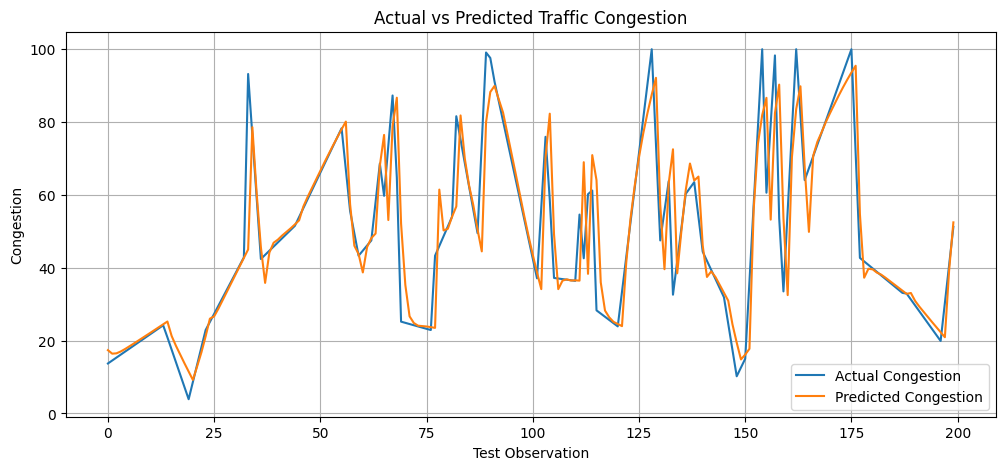

In [10]:
plt.figure(figsize=(12, 5))

plt.plot(y_actual[:200], label="Actual Congestion")
plt.plot(y_pred[:200], label="Predicted Congestion")

plt.title("Actual vs Predicted Traffic Congestion")
plt.xlabel("Test Observation")
plt.ylabel("Congestion")
plt.legend()
plt.grid(True)
plt.show()

In [11]:
last_24 = scaled[-sequence_length:]
next_input = last_24.reshape(1, sequence_length, 1)

next_scaled = model.predict(next_input, verbose=0)
next_congestion = scaler.inverse_transform(next_scaled)

print("Predicted congestion for the next hour:",
      round(float(next_congestion[0, 0]), 4))

Predicted congestion for the next hour: 44.6579


In [12]:
results = []

for units in [16, 32, 64]:
    temp_model = Sequential([
        tf.keras.Input(shape=(sequence_length, 1)),
        LSTM(units),
        Dense(1)
    ])

    temp_model.compile(
        optimizer="adam",
        loss="mse"
    )

    temp_model.fit(
        X_train, y_train,
        epochs=5,
        batch_size=32,
        validation_split=0.1,
        verbose=0
    )

    val_loss = temp_model.evaluate(
        X_test, y_test, verbose=0
    )

    results.append((units, val_loss))

print("Units and evaluation loss:")
for units, loss in results:
    print("Units:", units, "Loss:", round(loss, 5))

best_units = min(results, key=lambda x: x[1])[0]
print("Best units in this experiment:", best_units)

Units and evaluation loss:
Units: 16 Loss: 0.01326
Units: 32 Loss: 0.01326
Units: 64 Loss: 0.01322
Best units in this experiment: 64
